# 02 — Phân tích dữ liệu và biểu đồ

**Câu hỏi:** churn liên quan tới vòng đời, thiết bị, value/phí và sử dụng ra sao?

Chạy độc lập bằng Restart Kernel → Run All sau notebook 01.
Kiểm tra manifest, schema và hash trước khi phân tích.
Mỗi phần gồm câu hỏi, biểu đồ risk/reach, bảng số và nhận xét tính từ dữ liệu.

## 1. Import thư viện

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

## 2. Đường dẫn và xác nhận dữ liệu đã xử lý
Thiếu artifact hoặc hash sai sẽ có thông báo yêu cầu chạy lại notebook 01.

In [2]:
# Tìm project bằng đường dẫn tương đối từ thư mục làm việc.
root_candidates = [Path("."), *[Path("../" * level) for level in range(1, 7)]]
project_root = next(
    (path for path in root_candidates
     if (path / "data" / "cell2celltrain.csv").is_file()
     and (path / "work" / "pipeline").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Mở notebook từ project root hoặc work/pipeline; "
        "cần data/cell2celltrain.csv và work/pipeline/."
    )

source_path = project_root / "data" / "cell2celltrain.csv"
build_dir = project_root / "work" / "build"
processed_path = build_dir / "processed_customers.parquet"
qa_path = build_dir / "qa_report.json"
manifest_path = build_dir / "preparation_manifest.json"
display(pd.DataFrame({
    "Thành phần": ["Nguồn raw", "Processed", "Manifest"],
    "Đường dẫn tương đối": [str(source_path), str(processed_path), str(manifest_path)],
    "Tồn tại": [source_path.is_file(), processed_path.is_file(), manifest_path.is_file()],
}))

,Thành phần,Đường dẫn tương đối,Tồn tại
0,Nguồn raw,..\..\data\cell2celltrain.csv,True
1,Processed,..\..\work\build\processed_customers.parquet,True
2,Manifest,..\..\work\build\preparation_manifest.json,True


In [3]:
FEATURES = [
    "MonthsInService", "CurrentEquipmentDays", "HandsetWebCapable",
    "MonthlyRevenue", "TotalRecurringCharge", "CreditRating",
    "MonthlyMinutes", "PercChangeMinutes", "PercChangeRevenues", "PeakCallsInOut",
]
CATEGORICAL = ["HandsetWebCapable", "CreditRating"]
NUMERIC = [column for column in FEATURES if column not in CATEGORICAL]
BAND_COLUMNS = [
    "TenureBand", "EquipmentAgeBand", "ValueTier", "ChargeBand",
    "MinutesBand", "UsageTrendBand", "RevenueTrendBand",
]

In [4]:
missing_files = [
    str(path) for path in [processed_path, qa_path, manifest_path] if not path.is_file()
]
if missing_files:
    raise FileNotFoundError(
        "Chưa có dữ liệu được xác nhận. Chạy notebook 01 bằng Run All trước. "
        f"Thiếu: {missing_files}"
    )
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
qa = json.loads(qa_path.read_text(encoding="utf-8"))
if manifest.get("status") != "passed" or manifest.get("schema_version") != 1:
    raise ValueError("Manifest chưa PASS hoặc sai phiên bản; chạy lại notebook 01.")

for path, key in [
    (source_path, "source_sha256"),
    (processed_path, "processed_sha256"),
    (qa_path, "qa_sha256"),
]:
    if hashlib.sha256(path.read_bytes()).hexdigest() != manifest[key]:
        raise ValueError(f"{path.name} đã thay đổi; chạy lại notebook 01.")

data = pd.read_parquet(processed_path)
required = ["CustomerID", "Churn", *FEATURES, *BAND_COLUMNS]
if not set(required).issubset(data.columns):
    raise ValueError("Processed thiếu cột; chạy lại notebook 01.")
input_checks = pd.Series({
    "Số dòng khớp manifest/QA": len(data) == manifest["rows"] == qa["raw_rows"],
    "ID hợp lệ": data.CustomerID.notna().all() and data.CustomerID.is_unique,
    "Target nhị phân": data.Churn.isin([0, 1]).all(),
    "Churner khớp QA": int(data.Churn.sum()) == qa["target_counts"]["Yes"],
    "Numeric đúng kiểu": all(pd.api.types.is_numeric_dtype(data[c]) for c in NUMERIC),
    "Categorical không thiếu": not data[CATEGORICAL].isna().any().any(),
    "Band không thiếu": not data[BAND_COLUMNS].isna().any().any(),
}, name="PASS")
display(input_checks.to_frame())
if not input_checks.all():
    raise ValueError("Processed không hợp lệ; xem bảng kiểm tra và chạy lại notebook 01.")
print("INPUT PASS — schema, QA và SHA256 xác nhận dữ liệu đã xử lý.")

,PASS
Số dòng khớp manifest/QA,True
ID hợp lệ,True
Target nhị phân,True
Churner khớp QA,True
Numeric đúng kiểu,True
Categorical không thiếu,True
Band không thiếu,True


INPUT PASS — schema, QA và SHA256 xác nhận dữ liệu đã xử lý.


## 3. Công thức và hàm vẽ
Rate = churner/n cùng nhóm. Wilson CI 95% thể hiện bất định; risk luôn đọc cùng reach.

In [5]:
plt.rcParams.update({"figure.figsize": (12, 4), "font.size": 10})
analysis_tables = []

def group_summary(frame, column):
    summary = frame.groupby(column, observed=True, dropna=False).Churn.agg(
        n="size", churners="sum",
    ).reset_index()
    summary[column] = summary[column].astype(str)
    summary["rate"] = summary.churners / summary.n
    z = 1.96
    denominator = 1 + z**2 / summary.n
    center = (summary.rate + z**2 / (2 * summary.n)) / denominator
    margin = z * np.sqrt(
        summary.rate * (1 - summary.rate) / summary.n + z**2 / (4 * summary.n**2)
    ) / denominator
    summary["low"], summary["high"] = center - margin, center + margin
    if summary.n.sum() != len(frame) or summary.churners.sum() != frame.Churn.sum():
        raise ValueError(f"{column}: tổng nhóm không khớp cohort.")
    return summary

In [6]:
def plot_risk_reach(column, title, order):
    table = group_summary(data, column)
    positions = {label: index for index, label in enumerate(order)}
    table = table.sort_values(column, key=lambda s: s.map(positions).fillna(len(order)))
    table = table.reset_index(drop=True)
    x = np.arange(len(table))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].bar(x, table.rate, color="#1769aa")
    axes[0].errorbar(
        x, table.rate,
        yerr=[np.maximum(0, table.rate - table.low), np.maximum(0, table.high - table.rate)],
        fmt="none", color="#64788b", capsize=4,
    )
    axes[0].set(ylabel="Tỷ lệ churn", title="Risk — Wilson CI 95%")
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    axes[1].bar(x, table.n, color="#00a99b")
    axes[1].set(ylabel="Số khách", title="Reach — quy mô")
    for ax in axes:
        ax.set_xticks(x, table[column], rotation=25, ha="right")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    display(table)
    analysis_tables.append(table.rename(columns={column: "Group"}).assign(Dimension=column))
    return table

def compare_groups(table, column, left, right):
    indexed = table.set_index(column)
    if left not in indexed.index or right not in indexed.index:
        display(Markdown("**Chưa kết luận:** thiếu một nhóm so sánh."))
        return
    a, b = indexed.loc[left], indexed.loc[right]
    display(Markdown(
        f"**Quan sát:** {left}: **{a.rate:.2%}** ({int(a.churners):,}/{int(a.n):,}); "
        f"{right}: **{b.rate:.2%}** ({int(b.churners):,}/{int(b.n):,}). "
        f"Chênh **{100 * (a.rate - b.rate):+.2f} điểm phần trăm**."
    ))

## 4. Vòng đời
So sánh churn rate và quy mô theo TenureBand.

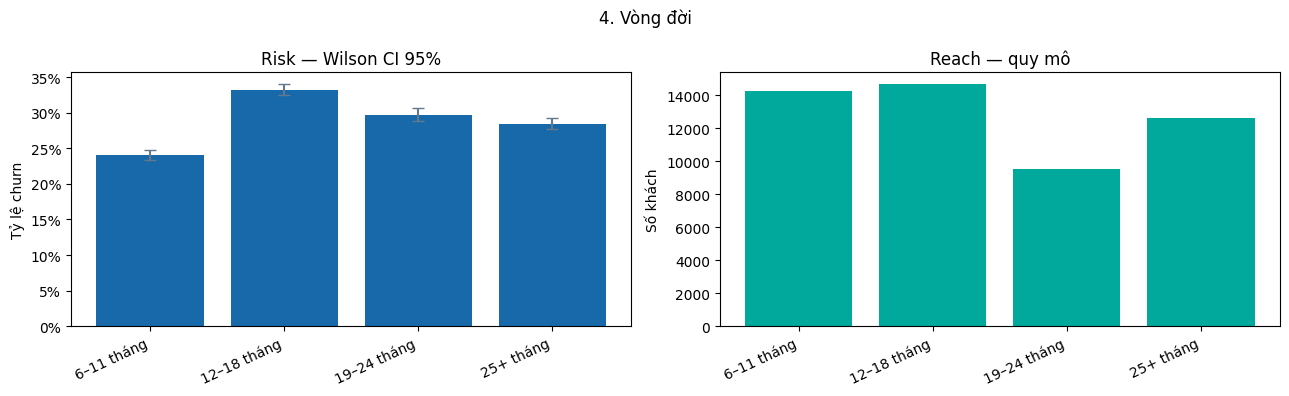

,TenureBand,n,churners,rate,low,high
0,6–11 tháng,14238,3421,0.240273,0.233325,0.247360
1,12–18 tháng,14654,4865,0.331991,0.324411,0.339659
2,19–24 tháng,9505,2825,0.297212,0.288107,0.306481
3,25+ tháng,12650,3600,0.284585,0.276788,0.292513


In [7]:
table_TenureBand = plot_risk_reach(
    'TenureBand',
    '4. Vòng đời',
    ['6–11 tháng', '12–18 tháng', '19–24 tháng', '25+ tháng'],
)

In [8]:
compare_groups(
    table_TenureBand, 'TenureBand',
    '12–18 tháng', '6–11 tháng',
)

**Quan sát:** 12–18 tháng: **33.20%** (4,865/14,654); 6–11 tháng: **24.03%** (3,421/14,238). Chênh **+9.17 điểm phần trăm**.

### Diễn giải và hướng hành động
Nhóm risk cao và reach lớn đáng thử lifecycle check-in. Tenure band là so sánh giữa khách trong snapshot, không phải chuỗi thời gian.

## 5. Tuổi thiết bị
So sánh churn rate và quy mô theo EquipmentAgeBand.

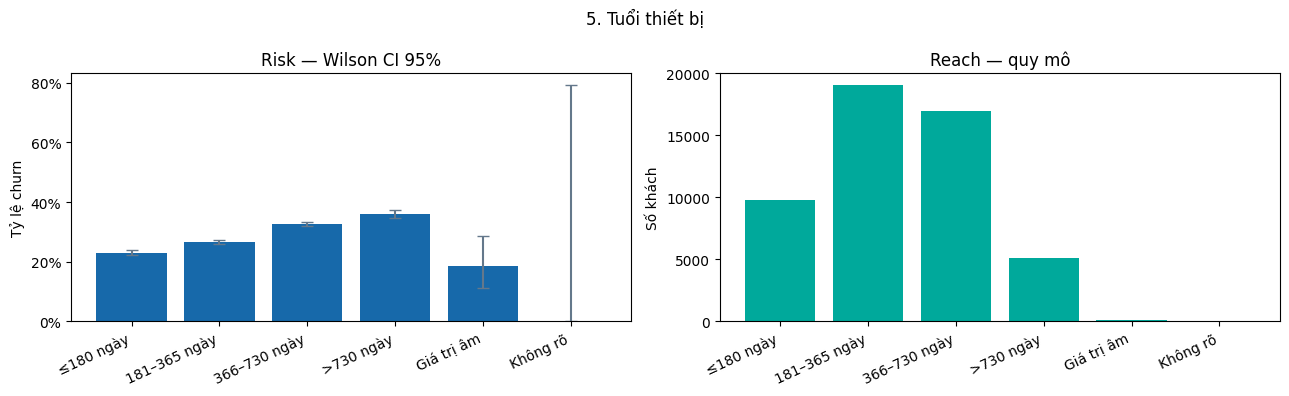

,EquipmentAgeBand,n,churners,rate,low,high
0,≤180 ngày,9759,2238,0.229327,0.221093,0.237773
1,181–365 ngày,19084,5077,0.266034,0.259812,0.272350
2,366–730 ngày,16986,5527,0.325386,0.318380,0.332470
3,>730 ngày,5141,1855,0.360825,0.347805,0.374052
4,Giá trị âm,76,14,0.184211,0.113025,0.285785
5,Không rõ,1,0,0.000000,0.000000,0.793457


In [9]:
table_EquipmentAgeBand = plot_risk_reach(
    'EquipmentAgeBand',
    '5. Tuổi thiết bị',
    ['≤180 ngày', '181–365 ngày', '366–730 ngày', '>730 ngày', 'Giá trị âm', 'Không rõ'],
)

In [10]:
compare_groups(
    table_EquipmentAgeBand, 'EquipmentAgeBand',
    '>730 ngày', '≤180 ngày',
)

**Quan sát:** >730 ngày: **36.08%** (1,855/5,141); ≤180 ngày: **22.93%** (2,238/9,759). Chênh **+13.15 điểm phần trăm**.

### Diễn giải và hướng hành động
Thiết bị cũ là tín hiệu rà soát trải nghiệm. Chưa chứng minh upgrade sẽ làm giảm churn. Giữ nhãn âm/Không rõ riêng.

## 6. Web capability
So sánh churn rate và quy mô theo HandsetWebCapable.

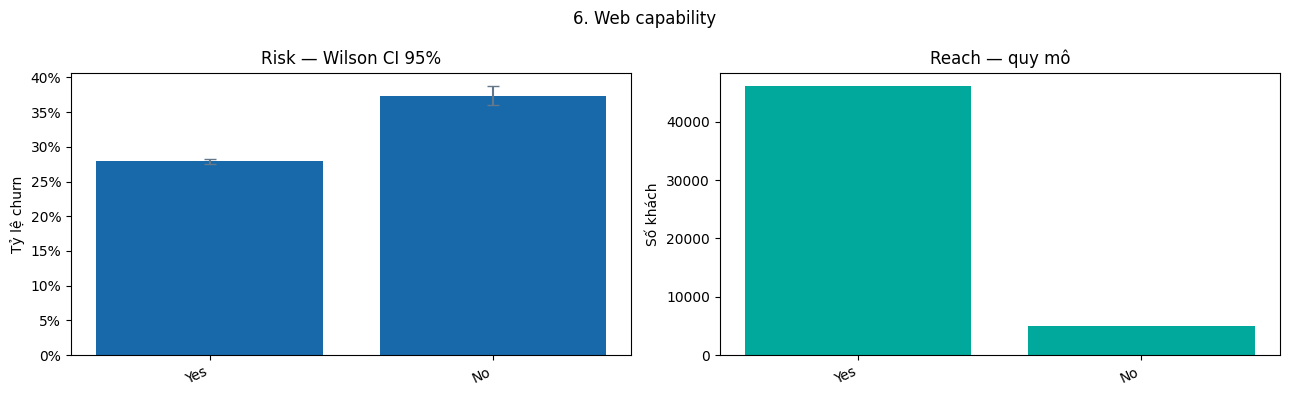

,HandsetWebCapable,n,churners,rate,low,high
0,Yes,46046,12843,0.278917,0.274839,0.283031
1,No,5001,1868,0.373525,0.360220,0.387025


In [11]:
table_HandsetWebCapable = plot_risk_reach(
    'HandsetWebCapable',
    '6. Web capability',
    ['Yes', 'No'],
)

In [12]:
compare_groups(
    table_HandsetWebCapable, 'HandsetWebCapable',
    'No', 'Yes',
)

**Quan sát:** No: **37.35%** (1,868/5,001); Yes: **27.89%** (12,843/46,046). Chênh **+9.46 điểm phần trăm**.

### Diễn giải và hướng hành động
Nên đọc cùng tuổi thiết bị và tenure vì các nhóm có thể khác đặc điểm khách hàng.

## 7. Value tier
So sánh churn rate và quy mô theo ValueTier.

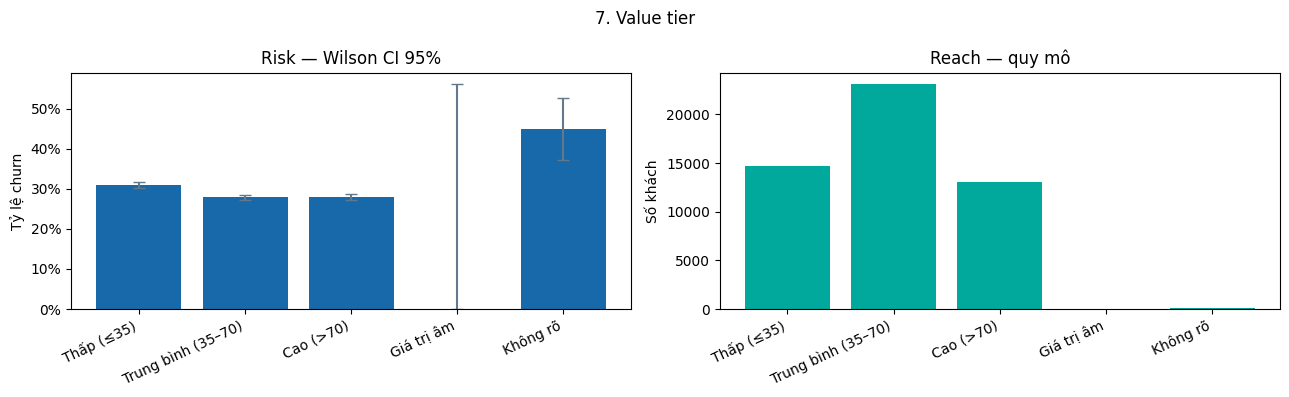

,ValueTier,n,churners,rate,low,high
0,Thấp (≤35),14703,4557,0.309937,0.302512,0.317461
1,Trung bình (35–70),23121,6438,0.278448,0.272708,0.284262
2,Cao (>70),13064,3646,0.279088,0.271462,0.286843
3,Giá trị âm,3,0,0.000000,0.000000,0.561506
4,Không rõ,156,70,0.448718,0.372835,0.527066


In [13]:
table_ValueTier = plot_risk_reach(
    'ValueTier',
    '7. Value tier',
    ['Thấp (≤35)', 'Trung bình (35–70)', 'Cao (>70)', 'Giá trị âm', 'Không rõ'],
)

In [14]:
compare_groups(
    table_ValueTier, 'ValueTier',
    'Thấp (≤35)', 'Cao (>70)',
)

**Quan sát:** Thấp (≤35): **30.99%** (4,557/14,703); Cao (>70): **27.91%** (3,646/13,064). Chênh **+3.08 điểm phần trăm**.

### Diễn giải và hướng hành động
MonthlyRevenue chỉ là proxy giá trị hiện tại. Ưu tiên value cao còn cần risk và cost; chưa phải CLV.

## 8. Phí định kỳ
So sánh churn rate và quy mô theo ChargeBand.

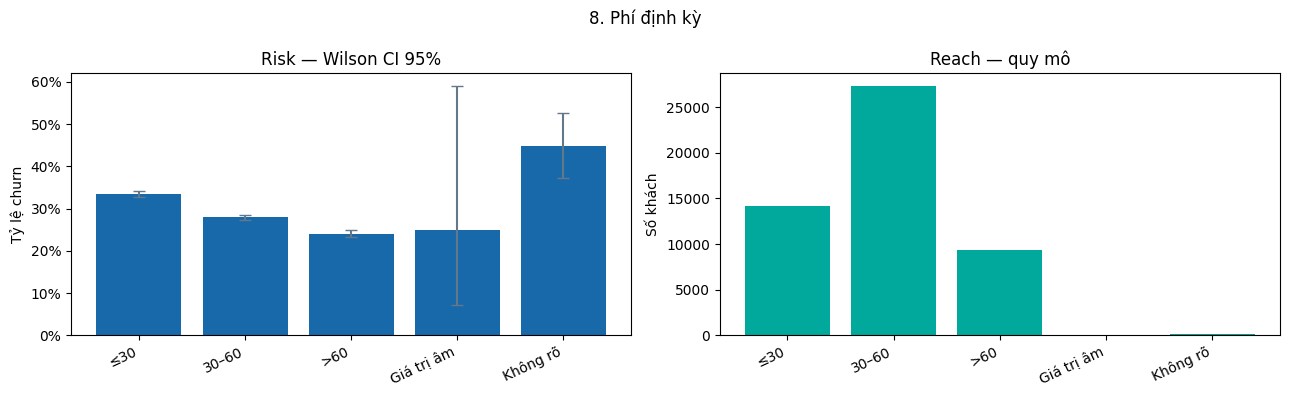

,ChargeBand,n,churners,rate,low,high
0,≤30,14168,4747,0.335051,0.327324,0.342867
1,30–60,27353,7642,0.279384,0.274098,0.284733
2,>60,9362,2250,0.240333,0.231785,0.249094
3,Giá trị âm,8,2,0.250000,0.071478,0.590730
4,Không rõ,156,70,0.448718,0.372835,0.527066


In [15]:
table_ChargeBand = plot_risk_reach(
    'ChargeBand',
    '8. Phí định kỳ',
    ['≤30', '30–60', '>60', 'Giá trị âm', 'Không rõ'],
)

In [16]:
compare_groups(
    table_ChargeBand, 'ChargeBand',
    '≤30', '>60',
)

**Quan sát:** ≤30: **33.51%** (4,747/14,168); >60: **24.03%** (2,250/9,362). Chênh **+9.47 điểm phần trăm**.

### Diễn giải và hướng hành động
Không suy ra tăng phí làm giảm churn. Loại gói, usage và tenure có thể là yếu tố gây nhiễu.

## 9. Cường độ sử dụng
So sánh churn rate và quy mô theo MinutesBand.

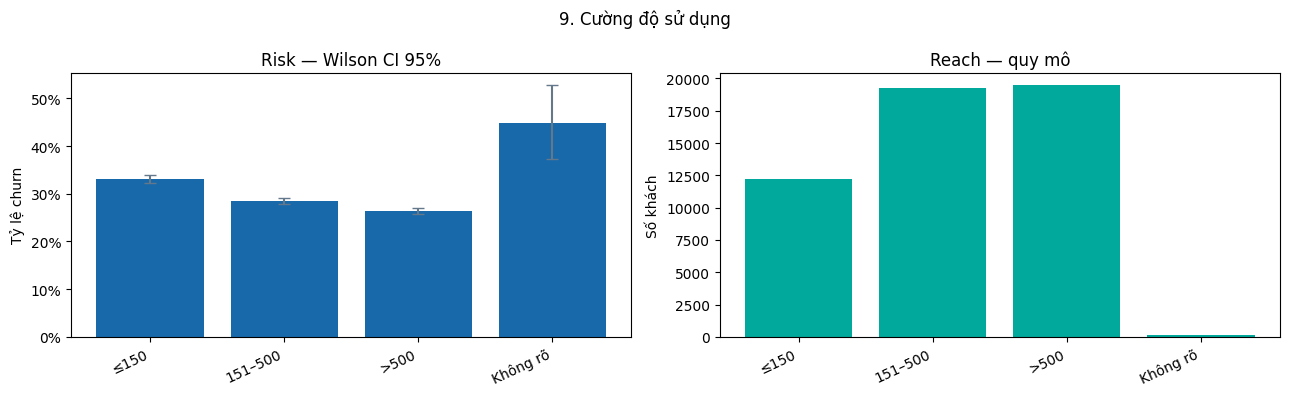

,MinutesBand,n,churners,rate,low,high
0,≤150,12214,4044,0.331095,0.322804,0.339494
1,151–500,19225,5465,0.284265,0.277933,0.290684
2,>500,19452,5132,0.263829,0.257683,0.270068
3,Không rõ,156,70,0.448718,0.372835,0.527066


In [17]:
table_MinutesBand = plot_risk_reach(
    'MinutesBand',
    '9. Cường độ sử dụng',
    ['≤150', '151–500', '>500', 'Không rõ'],
)

In [18]:
compare_groups(
    table_MinutesBand, 'MinutesBand',
    '≤150', '>500',
)

**Quan sát:** ≤150: **33.11%** (4,044/12,214); >500: **26.38%** (5,132/19,452). Chênh **+6.73 điểm phần trăm**.

### Diễn giải và hướng hành động
Low engagement đáng khám phá; usage thấp chưa chứng minh khách không hài lòng.

## 10. Thay đổi sử dụng
So sánh churn rate và quy mô theo UsageTrendBand.

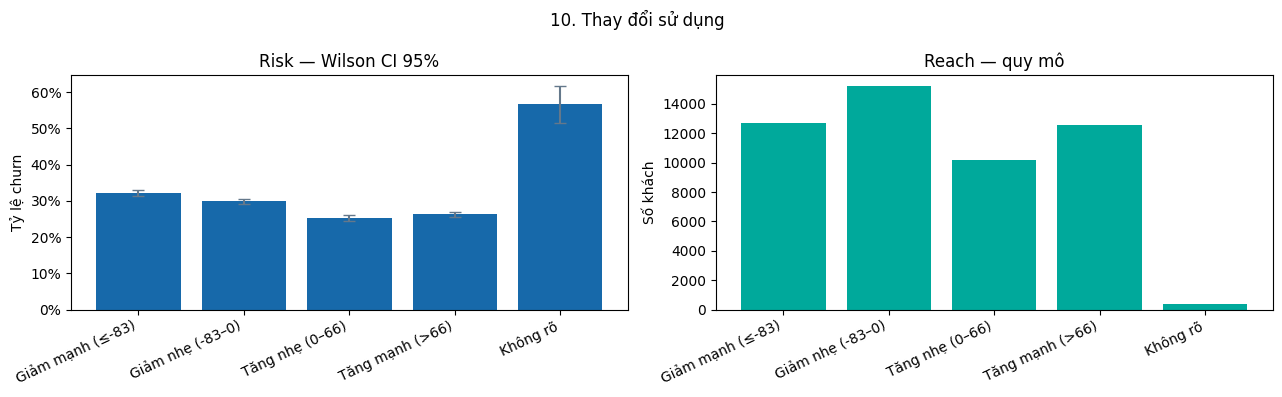

,UsageTrendBand,n,churners,rate,low,high
0,Giảm mạnh (≤-83),12728,4090,0.321339,0.313281,0.329505
1,Giảm nhẹ (-83–0),15212,4546,0.298843,0.291620,0.306167
2,Tăng nhẹ (0–66),10178,2572,0.252702,0.244354,0.261237
3,Tăng mạnh (>66),12562,3295,0.262299,0.254680,0.270063
4,Không rõ,367,208,0.566757,0.515627,0.616505


In [19]:
table_UsageTrendBand = plot_risk_reach(
    'UsageTrendBand',
    '10. Thay đổi sử dụng',
    ['Giảm mạnh (≤-83)', 'Giảm nhẹ (-83–0)', 'Tăng nhẹ (0–66)', 'Tăng mạnh (>66)', 'Không rõ'],
)

In [20]:
compare_groups(
    table_UsageTrendBand, 'UsageTrendBand',
    'Giảm mạnh (≤-83)', 'Tăng nhẹ (0–66)',
)

**Quan sát:** Giảm mạnh (≤-83): **32.13%** (4,090/12,728); Tăng nhẹ (0–66): **25.27%** (2,572/10,178). Chênh **+6.86 điểm phần trăm**.

### Diễn giải và hướng hành động
Thử re-engagement sau khi xác minh đơn vị và lead time. Missing có thể mang tín hiệu riêng.

## 11. Đối soát và xuất bảng
Không hard-code tỷ lệ kỳ vọng. Mọi dimension phải cộng về đúng số khách và churner.

In [21]:
summary = pd.concat(analysis_tables, ignore_index=True)
totals = summary.groupby("Dimension")[["n", "churners"]].sum()
display(totals)
if not totals.n.eq(len(data)).all() or not totals.churners.eq(data.Churn.sum()).all():
    raise ValueError("Có dimension không đối soát được.")
summary.to_csv(build_dir / "eda_group_summary.csv", index=False, encoding="utf-8-sig")
insights = {
    "source_sha256": manifest["source_sha256"],
    "processed_sha256": manifest["processed_sha256"],
    "baseline_churn_rate": float(data.Churn.mean()),
    "dimensions": sorted(summary.Dimension.unique().tolist()),
    "interpretation": "Observed associations; not causal effects.",
}
(build_dir / "eda_insights.json").write_text(
    json.dumps(insights, ensure_ascii=False, indent=2), encoding="utf-8",
)
print("02 PASS — mọi dimension đối soát; bảng EDA đã xuất.")

,n,churners
Dimension,,
ChargeBand,51047,14711
EquipmentAgeBand,51047,14711
HandsetWebCapable,51047,14711
MinutesBand,51047,14711
TenureBand,51047,14711
UsageTrendBand,51047,14711
ValueTier,51047,14711


02 PASS — mọi dimension đối soát; bảng EDA đã xuất.


### Kết luận chung
Đọc risk cùng reach và CI. Các tín hiệu là cơ sở tạo giả thuyết; cần treatment/control để kiểm chứng. Notebook 03 kiểm tra khả năng kết hợp feature thành score.